In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
np.random.seed(1)
X = np.linspace(0,5,40); y = np.sin(X) + np.random.normal(0,0.3,40)
X_test = np.linspace(0,5,20); y_true = np.sin(X_test)

In [3]:
degrees = [1,2,3,4,6,9]; B,V,T = [],[],[]
for d in degrees:
    preds = []
    for _ in range(100):                                  # bootstrap resampling
        idx = np.random.choice(len(X),len(X),replace=True)
        preds.append(np.polyval(np.polyfit(X[idx],y[idx],d), X_test))
    preds = np.array(preds)
    bias2 = np.mean((preds.mean(axis=0)-y_true)**2)       # how far average prediction is from truth
    var   = np.mean(preds.var(axis=0))                    # how much predictions vary
    B.append(bias2); V.append(var); T.append(bias2+var)
    print(f"Degree {d}: Bias^2={bias2:.4f}  Variance={var:.4f}  Total={bias2+var:.4f}")

Degree 1: Bias^2=0.1978  Variance=0.0154  Total=0.2132
Degree 2: Bias^2=0.0670  Variance=0.0222  Total=0.0892
Degree 3: Bias^2=0.0072  Variance=0.0176  Total=0.0248
Degree 4: Bias^2=0.0113  Variance=0.0139  Total=0.0252
Degree 6: Bias^2=0.0284  Variance=0.0634  Total=0.0919
Degree 9: Bias^2=0.1078  Variance=2.3060  Total=2.4138


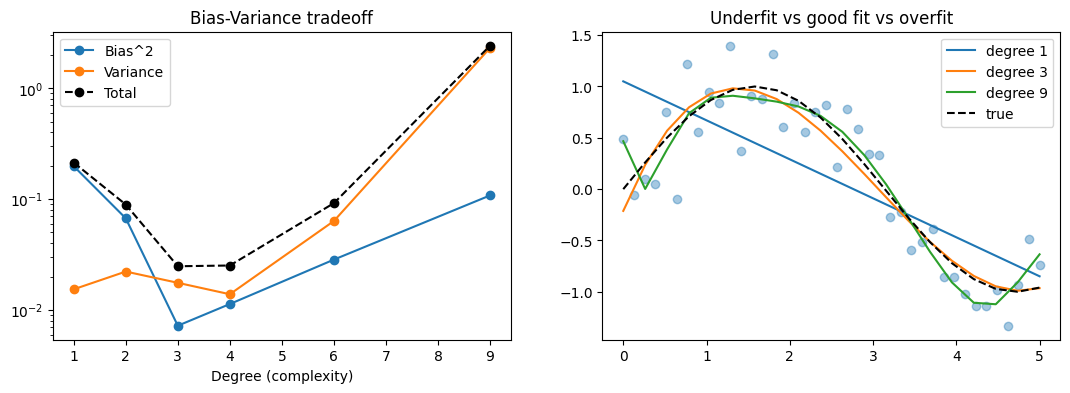

In [4]:
fig,ax = plt.subplots(1,2,figsize=(13,4))
ax[0].plot(degrees,B,"o-",label="Bias^2"); ax[0].plot(degrees,V,"o-",label="Variance")
ax[0].plot(degrees,T,"k--o",label="Total"); ax[0].set_yscale("log")
ax[0].set_xlabel("Degree (complexity)"); ax[0].legend(); ax[0].set_title("Bias-Variance tradeoff")
for d in [1,3,9]:
    ax[1].plot(X_test, np.polyval(np.polyfit(X,y,d),X_test), label=f"degree {d}")
ax[1].plot(X_test,y_true,"k--",label="true"); ax[1].scatter(X,y,alpha=.4); ax[1].legend()
ax[1].set_title("Underfit vs good fit vs overfit")
plt.show()